# **Problem Set 1**
## CHEM 5541 - Chemical Dynamics
### *Samuel Arnold*
### *9/4/26*
***

### 3. First Order Kinetics in Simulated Nuclear Decay

### a.)

$N_0$ = initial number of nuclei 
<br>
$p$ = probability of survival in each step

$N(t_i) = N_0 (p)^i$

In [ ]:
using DataFrames
using CSV

# Starting conditions
N_0 = 100
p = 0.8
max_steps = 30

step_numbers = []
N_i = []

N_current = N_0
for i in 1:max_steps
    survivors = 0
    for particle in 1:N_current
        if rand() < p
            survivors += 1
        end
    end
    
    N_current = survivors
    push!(step_numbers, i)
    push!(N_i, N_current)
end

println("Step i \t Remaining N(i)")
for idx in 1:length(step_numbers)
    println("$(step_numbers[idx]) \t $(N_i[idx])")
end


df = DataFrame(step_numbers = step_numbers, N_i = N_i)


open("S.Arnold_ProblemSet1_CHEM5541_decay.csv", "w") do io
    println(io, "# N0 = $N_0")
    println(io, "# p = $p")
    CSV.write(io, df; append=true, writeheader=true)
end

# print(df)

Step i 	 Remaining N(i)
1 	 78
2 	 66
3 	 51
4 	 43
5 	 36
6 	 25
7 	 21
8 	 14
9 	 9
10 	 6
11 	 4
12 	 3
13 	 3
14 	 2
15 	 2
16 	 0
17 	 0
18 	 0
19 	 0
20 	 0
21 	 0
22 	 0
23 	 0
24 	 0
25 	 0
26 	 0
27 	 0
28 	 0
29 	 0
30 	 0


IOStream(<file S.Arnold_ProblemSet1_CHEM5541_decay.csv>)

***
### b.)

Differential:

$\frac{dN(t_i)}{dt} = \ln(p) N(t_i)$

Integrated:

$N(t_i) = N_0 (p)^i$

For finding $i_{1/2}$

$\ln(\frac{N(t_i)}{N_0}) = \ln(p) t_i$

$i_{1/2, calc} = \frac{-\ln(2)}{\ln(p)}$

Calculated Half-Life (i_1/2): = 3.106 steps
Experimental Half-Life (i_1/2): 2.375 steps


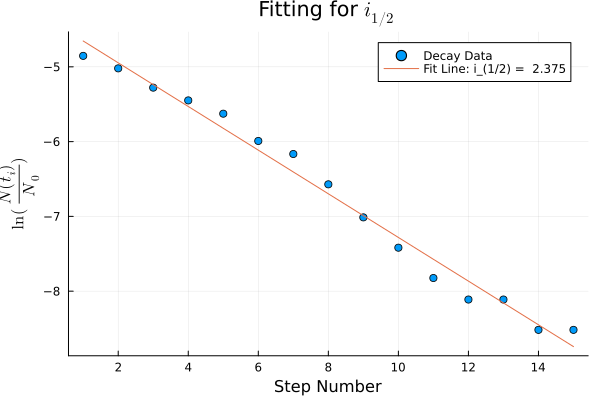

In [147]:
using Plots
using Statistics

gr()

df_filtered = filter(row -> row.N_i > 0, df)

nuclei_ratio = log.(df_filtered[!, "N_i"] / N_0)


step_range_fit = df_filtered[!, "step_numbers"]

mean_step_range_fit = mean(step_range_fit)
mean_nuclei_ratio = mean(nuclei_ratio)

numerator = sum((step_range_fit .- mean_step_range_fit) .* (nuclei_ratio .- mean_nuclei_ratio))
denominator = sum((step_range_fit .- mean_step_range_fit).^2)
slope = numerator / denominator

intercept = mean_nuclei_ratio - (slope * mean_step_range_fit)

experimental_i_half = -log(2) / slope

calc_i_half = abs(log(2) / log(p))

println("Calculated Half-Life (i_1/2): = ", round(calc_i_half, digits=3), " steps")
println("Experimental Half-Life (i_1/2): ", round(experimental_i_half, digits=3), " steps")

fit_line = slope .* step_range_fit .+ intercept

scatter(
    step_range_fit, 
    nuclei_ratio,
    title=raw"Fitting for $i_{1/2}$", 
    label="Decay Data",
    xlabel="Step Number", 
    ylabel=raw"$\ln(\frac{N(t_i)}{N_0})$"
)

plot!(
    step_range_fit,
    fit_line,
    label="Fit Line: i_(1/2) =  $(round(experimental_i_half, digits=3))", # LaTeX formatting was breaking here
)

In [144]:
using Plots
using Statistics

gr()

N_0 = 100
p = 0.8
max_steps = 30
total_runs = 5

half_lives_all_runs = []

calc_i_half = abs(log(2) / log(p))

println("Calculated Half-Life (i_1/2): = ", round(calc_i_half, digits=3), " steps")

for run in 1:total_runs

    step_numbers = []
    N_i = []
    N_current = N_0
    
    for i in 1:max_steps
        survivors = 0
        for particle in 1:N_current
            if rand() < p
                survivors += 1
            end
        end
        N_current = survivors
        
        push!(step_numbers, i)
        push!(N_i, N_current)
    end
    
    zero_mask = N_i .> 0
    step_range_fit = step_numbers[zero_mask]
    nuclei_ratio = log.(N_i[zero_mask] / N_0)
    
    mean_step_range_fit = mean(step_range_fit)
    mean_nuclei_ratio = mean(nuclei_ratio)
    
    numerator = sum((step_range_fit .- mean_step_range_fit) .* (nuclei_ratio .- mean_nuclei_ratio))
    denominator = sum((step_range_fit .- mean_step_range_fit).^2)
    slope = numerator / denominator
    intercept = mean_nuclei_ratio - (slope * mean_step_range_fit)
    
    experimental_i_half = -log(2) / slope
    push!(half_lives_all_runs, experimental_i_half)

    println("| Run $run Experimental Half-Life (i_1/2): | ", round(experimental_i_half, digits=3), " steps")
    println("| Run $run Slope: | ", round(slope, digits=3))

end

mean_half_life = mean(half_lives_all_runs)
std_half_life = std(half_lives_all_runs)

println("Mean Experimental Half-Life: ", round(mean_half_life, digits=3), " steps")
println("Standard Deviation:      ", round(std_half_life, digits=3), " steps")

Calculated Half-Life (i_1/2): = 3.106 steps
| Run 1 Experimental Half-Life (i_1/2): | 3.249 steps
| Run 1 Slope: | -0.213
| Run 2 Experimental Half-Life (i_1/2): | 2.543 steps
| Run 2 Slope: | -0.273
| Run 3 Experimental Half-Life (i_1/2): | 4.263 steps
| Run 3 Slope: | -0.163
| Run 4 Experimental Half-Life (i_1/2): | 3.455 steps
| Run 4 Slope: | -0.201
| Run 5 Experimental Half-Life (i_1/2): | 2.663 steps
| Run 5 Slope: | -0.26
Mean Experimental Half-Life: 3.235 steps
Standard Deviation:      0.691 steps


### c.)

$N_0 = 1000$

In [145]:
using Plots
using Statistics

gr()


N_0 = 1000
p = 0.8
max_steps = 30
total_runs = 5

half_lives_all_runs = []

calc_i_half = abs(log(2) / log(p))

println("Calculated Half-Life (i_1/2): = ", round(calc_i_half, digits=3), " steps")

for run in 1:total_runs

    step_numbers = []
    N_i = []
    N_current = N_0
    
    for i in 1:max_steps
        survivors = 0
        for particle in 1:N_current
            if rand() < p
                survivors += 1
            end
        end
        N_current = survivors
        
        push!(step_numbers, i)
        push!(N_i, N_current)
    end
    
    zero_mask = N_i .> 0
    step_range_fit = step_numbers[zero_mask]
    nuclei_ratio = log.(N_i[zero_mask] / N_0)
    
    mean_step_range_fit = mean(step_range_fit)
    mean_nuclei_ratio = mean(nuclei_ratio)
    
    numerator = sum((step_range_fit .- mean_step_range_fit) .* (nuclei_ratio .- mean_nuclei_ratio))
    denominator = sum((step_range_fit .- mean_step_range_fit).^2)
    slope = numerator / denominator
    intercept = mean_nuclei_ratio - (slope * mean_step_range_fit)
    
    experimental_i_half = -log(2) / slope
    push!(half_lives_all_runs, experimental_i_half)

    println("| Run $run Experimental Half-Life (i_1/2): | ", round(experimental_i_half, digits=3), " steps")
    println("| Run $run Slope: | ", round(slope, digits=3))
end

mean_half_life = mean(half_lives_all_runs)
std_half_life = std(half_lives_all_runs)

println("Mean Experimental Half-Life: ", round(mean_half_life, digits=3), " steps")
println("Standard Deviation:      ", round(std_half_life, digits=3), " steps")

Calculated Half-Life (i_1/2): = 3.106 steps
| Run 1 Experimental Half-Life (i_1/2): | 2.916 steps
| Run 1 Slope: | -0.238
| Run 2 Experimental Half-Life (i_1/2): | 2.726 steps
| Run 2 Slope: | -0.254
| Run 3 Experimental Half-Life (i_1/2): | 3.284 steps
| Run 3 Slope: | -0.211
| Run 4 Experimental Half-Life (i_1/2): | 3.221 steps
| Run 4 Slope: | -0.215
| Run 5 Experimental Half-Life (i_1/2): | 3.407 steps
| Run 5 Slope: | -0.203
Mean Experimental Half-Life: 3.111 steps
Standard Deviation:      0.281 steps


Having more particles to undergo the decay allows for the variability in the probablilty to be smoothed out more, allowing for the experimental values to be closer to the calculated value. Below, I went ahead and did $N_0 = 10,000$ to further support this logic.

In [146]:
using Plots
using Statistics

gr()


N_0 = 10000
p = 0.8
max_steps = 30
total_runs = 5

half_lives_all_runs = []

calc_i_half = abs(log(2) / log(p))

println("Calculated Half-Life (i_1/2): = ", round(calc_i_half, digits=3), " steps")

for run in 1:total_runs

    step_numbers = []
    N_i = []
    N_current = N_0
    
    for i in 1:max_steps
        survivors = 0
        for particle in 1:N_current
            if rand() < p
                survivors += 1
            end
        end
        N_current = survivors
        
        push!(step_numbers, i)
        push!(N_i, N_current)
    end
    
    zero_mask = N_i .> 0
    step_range_fit = step_numbers[zero_mask]
    nuclei_ratio = log.(N_i[zero_mask] / N_0)
    
    mean_step_range_fit = mean(step_range_fit)
    mean_nuclei_ratio = mean(nuclei_ratio)
    
    numerator = sum((step_range_fit .- mean_step_range_fit) .* (nuclei_ratio .- mean_nuclei_ratio))
    denominator = sum((step_range_fit .- mean_step_range_fit).^2)
    slope = numerator / denominator
    intercept = mean_nuclei_ratio - (slope * mean_step_range_fit)
    
    experimental_i_half = -log(2) / slope
    push!(half_lives_all_runs, experimental_i_half)

    println("| Run $run Experimental Half-Life (i_1/2): | ", round(experimental_i_half, digits=3), " steps")
    println("| Run $run Slope: | ", round(slope, digits=3))

end

mean_half_life = mean(half_lives_all_runs)
std_half_life = std(half_lives_all_runs)

println("Mean Experimental Half-Life: ", round(mean_half_life, digits=3), " steps")
println("Standard Deviation:      ", round(std_half_life, digits=3), " steps")

Calculated Half-Life (i_1/2): = 3.106 steps
| Run 1 Experimental Half-Life (i_1/2): | 3.003 steps
| Run 1 Slope: | -0.231
| Run 2 Experimental Half-Life (i_1/2): | 3.198 steps
| Run 2 Slope: | -0.217
| Run 3 Experimental Half-Life (i_1/2): | 3.157 steps
| Run 3 Slope: | -0.22
| Run 4 Experimental Half-Life (i_1/2): | 3.086 steps
| Run 4 Slope: | -0.225
| Run 5 Experimental Half-Life (i_1/2): | 3.236 steps
| Run 5 Slope: | -0.214
Mean Experimental Half-Life: 3.136 steps
Standard Deviation:      0.093 steps
